In [2]:
import pandas as pd
import numpy as np
from imblearn.over_sampling import RandomOverSampler
from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
    f1_score
)
import matplotlib.pyplot as plt
import seaborn as sns


In [ ]:
df = pd.read_csv("data/data_mlp_dt.csv")

In [5]:
# train test split
X = df.drop(columns=['IS_DELAYED'])
y = df['IS_DELAYED']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, shuffle=True, random_state=42, stratify=y
)

In [6]:
# Separate numeric and categorical columns
num_cols = X_train.select_dtypes(include=['int64', 'float64']).columns
cat_cols = X_train.select_dtypes(include=['object']).columns

# Scale numeric
scaler = StandardScaler()
X_train_num = scaler.fit_transform(X_train[num_cols])
X_test_num = scaler.transform(X_test[num_cols])

# Encode categorical
encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
X_train_cat = encoder.fit_transform(X_train[cat_cols])
X_test_cat = encoder.transform(X_test[cat_cols])

# Combine all features back
X_train_final = np.hstack([X_train_num, X_train_cat])
X_test_final = np.hstack([X_test_num, X_test_cat])

print(f"Final shape: {X_train_final.shape}")


Final shape: (932184, 748)


In [7]:
# Get feature names
num_feature_names = num_cols
cat_feature_names = encoder.get_feature_names_out(cat_cols)
all_feature_names = np.concatenate([num_feature_names, cat_feature_names])

# Convert back to DataFrame
X_train_final_df = pd.DataFrame(X_train_final, columns=all_feature_names)
X_test_final_df = pd.DataFrame(X_test_final, columns=all_feature_names)

X_train_final_df.head()


,DAY_OF_MONTH,DAY_OF_WEEK,DEP_TIME,ARR_TIME,DISTANCE,IS_WEEKEND,OP_CARRIER_9E,OP_CARRIER_AA,OP_CARRIER_AS,OP_CARRIER_B6,...,DEP_TIME_BLK_1400-1459,DEP_TIME_BLK_1500-1559,DEP_TIME_BLK_1600-1659,DEP_TIME_BLK_1700-1759,DEP_TIME_BLK_1800-1859,DEP_TIME_BLK_1900-1959,DEP_TIME_BLK_2000-2059,DEP_TIME_BLK_2100-2159,DEP_TIME_BLK_2200-2259,DEP_TIME_BLK_2300-2359
0,-1.213814,1.097910,-1.036592,-0.803972,-0.509930,1.808774,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.009892,0.054637,0.430237,0.624013,-0.071409,-0.552861,0.0,0.0,0.0,1.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.566122,-1.510273,-0.254820,-0.262520,-1.016177,-0.552861,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,-1.658799,-0.988636,1.453794,1.588713,-0.494692,-0.552861,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
4,1.678583,0.054637,0.154199,0.231270,-0.862102,-0.552861,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [10]:
ros = RandomOverSampler(sampling_strategy=0.3, random_state=42)
X_train_ros, y_train_ros = ros.fit_resample(X_train_final_df, y_train)

In [ ]:
dt = DecisionTreeClassifier(
    criterion='gini',
    class_weight='balanced',
    random_state=42
)

param_grid = {
    "max_depth": [15, 20, 25],
    "min_samples_split": [50, 100, 150],
    "min_samples_leaf": [20, 50, 100]
}

grid = GridSearchCV(
    estimator=dt,
    param_grid=param_grid,
    scoring="f1",
    n_jobs=1,           # prevent RAM spikes
    verbose=2,
    cv=3                # 3-fold CV (same as before)
)

grid.fit(X_train_ros, y_train_ros)

print("Best params:", grid.best_params_)
print("Best score:", grid.best_score_)

best_dt = grid.best_estimator_
y_pred = best_dt.predict(X_test_final_df)
y_proba = best_dt.predict_proba(X_test_final_df)[:, 1]

Fitting 3 folds for each of 27 candidates, totalling 81 fits
[CV] END max_depth=15, min_samples_leaf=20, min_samples_split=50; total time=  57.3s
[CV] END max_depth=15, min_samples_leaf=20, min_samples_split=50; total time=  58.5s
[CV] END max_depth=15, min_samples_leaf=20, min_samples_split=50; total time= 1.0min
[CV] END max_depth=15, min_samples_leaf=20, min_samples_split=100; total time=  59.4s
[CV] END max_depth=15, min_samples_leaf=20, min_samples_split=100; total time=  58.0s
[CV] END max_depth=15, min_samples_leaf=20, min_samples_split=100; total time= 1.1min
[CV] END max_depth=15, min_samples_leaf=20, min_samples_split=150; total time=  59.2s
[CV] END max_depth=15, min_samples_leaf=20, min_samples_split=150; total time=  57.1s
[CV] END max_depth=15, min_samples_leaf=20, min_samples_split=150; total time= 1.0min
[CV] END max_depth=15, min_samples_leaf=50, min_samples_split=50; total time= 1.0min
[CV] END max_depth=15, min_samples_leaf=50, min_samples_split=50; total time=  56.1

In [12]:
dt = DecisionTreeClassifier(
    max_depth=25,
    min_samples_leaf=20,
    min_samples_split=50,
    criterion='gini',
    class_weight='balanced',
    random_state=42
)

dt.fit(X_train_ros, y_train_ros)
y_pred = dt.predict(X_test_final_df)
y_proba = dt.predict_proba(X_test_final_df)[:, 1]

Accuracy: 0.8395044776375581
ROC-AUC: 0.8917002207272693
F1: 0.6490847851989454

Classification Report:
               precision    recall  f1-score   support

           0       0.94      0.86      0.90    187544
           1       0.57      0.76      0.65     45503

    accuracy                           0.84    233047
   macro avg       0.75      0.81      0.77    233047
weighted avg       0.86      0.84      0.85    233047



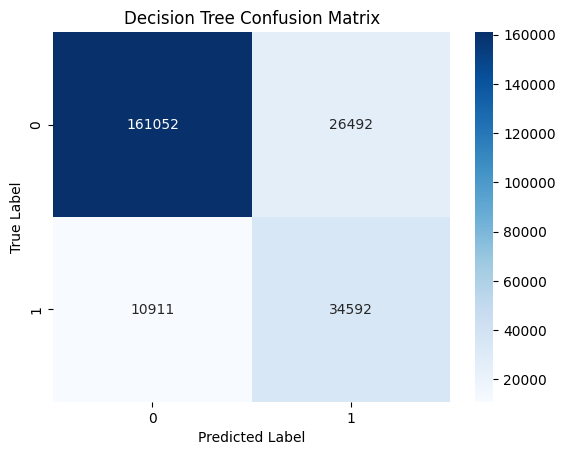

In [13]:
print("Accuracy:", accuracy_score(y_test, y_pred))
print("ROC-AUC:", roc_auc_score(y_test, y_proba))
print("F1:", f1_score(y_test, y_pred))

print("\nClassification Report:\n", classification_report(y_test, y_pred))

cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Decision Tree Confusion Matrix")
plt.show()

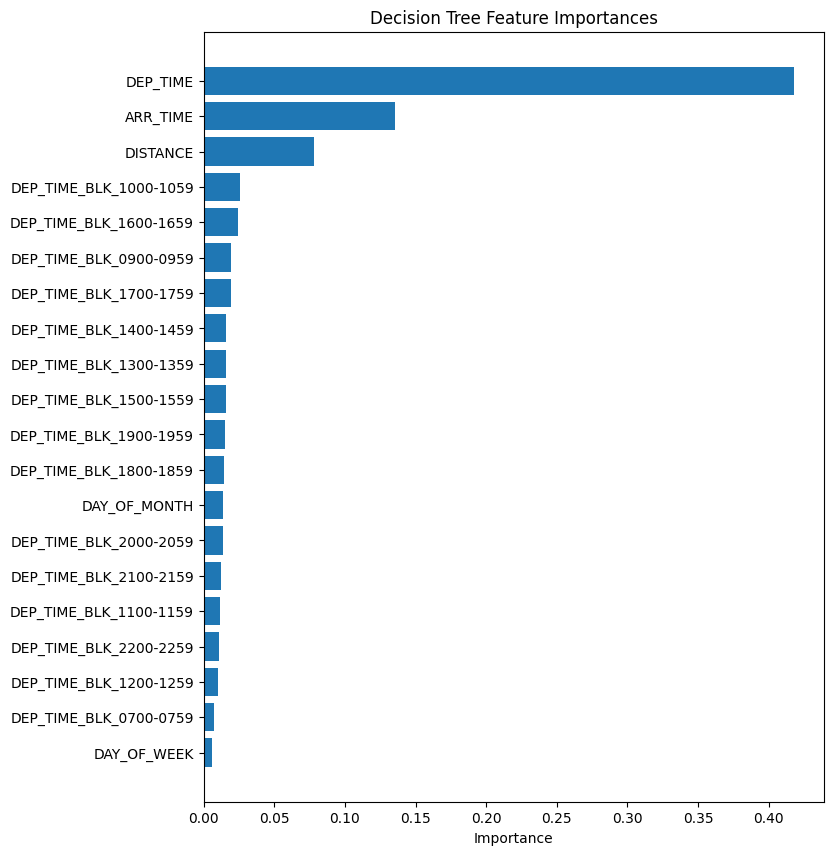

In [ ]:
importances = best_dt.feature_importances_

# Get corresponding feature names
feature_names = X_train_ros.columns if hasattr(X_train_ros, "columns") else [f"f{i}" for i in range(X_train_ros.shape[1])]

idx = np.argsort(importances)[-20:]  # top 20

plt.figure(figsize=(8,10))
plt.barh(np.array(feature_names)[idx], importances[idx])
plt.xlabel("Importance")
plt.title("Decision Tree Feature Importances")
plt.show()

In [ ]:
rf = RandomForestClassifier(
    class_weight='balanced',
    max_samples=0.7,
    max_features="sqrt",
    n_jobs=2,
    random_state=42
)

param_dist = {
    "n_estimators": [100, 150, 200],
    "max_depth": [None, 40, 60, 80],
    "min_samples_split": [5, 10],
    "min_samples_leaf": [1, 5]
}

rf_random = RandomizedSearchCV(
    estimator=rf,
    param_distributions=param_dist,
    n_iter=10,
    scoring="f1",
    cv=3,
    n_jobs=2,
    verbose=2,
    random_state=42
)

# run search
rf_random.fit(X_train_final_df, y_train)

print("Best Params:", rf_random.best_params_)
print("Best f1:", rf_random.best_score_)

Fitting 3 folds for each of 10 candidates, totalling 30 fits


/usr/local/lib/python3.12/dist-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


Best Params: {'n_estimators': 150, 'min_samples_split': 10, 'min_samples_leaf': 1, 'max_depth': 80}
Best f1: 0.7121667087158685


In [19]:
rf = RandomForestClassifier(
    n_estimators=150,
    min_samples_split=10,
    min_samples_leaf=1,
    max_depth = 60,
    max_samples=0.7,
    class_weight='balanced',
    n_jobs=2,
    random_state=42
)

rf.fit(X_train_final_df, y_train)
y_pred_rf = rf.predict(X_test_final_df)
y_proba_rf = rf.predict_proba(X_test_final_df)[:, 1]


ROC-AUC: 0.9151332708488576

Classification Report:
               precision    recall  f1-score   support

           0       0.92      0.96      0.94    187544
           1       0.80      0.67      0.73     45503

    accuracy                           0.90    233047
   macro avg       0.86      0.81      0.83    233047
weighted avg       0.90      0.90      0.90    233047



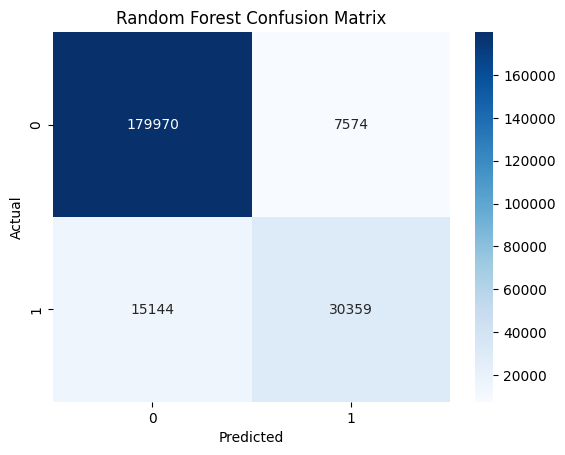

In [20]:
print("ROC-AUC:", roc_auc_score(y_test, y_proba_rf))
print("\nClassification Report:\n", classification_report(y_test, y_pred_rf))

# Confusion matrix
cm = confusion_matrix(y_test, y_pred_rf)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

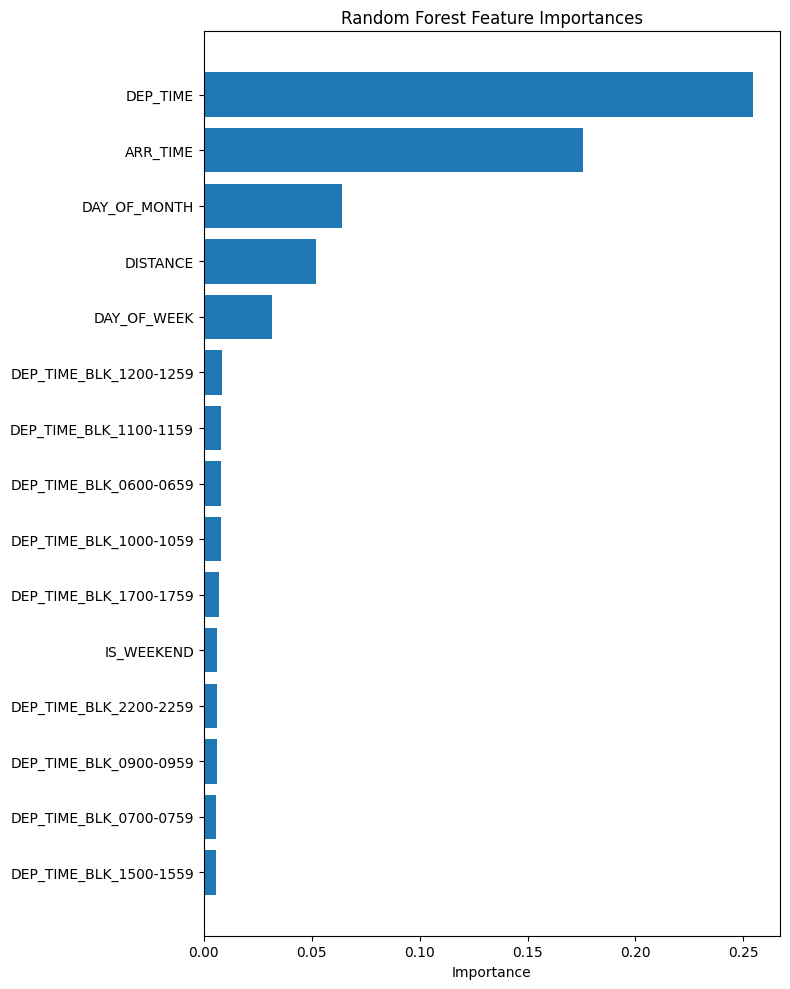

In [23]:
importances = rf.feature_importances_

# Get feature names
if hasattr(X_train_final_df, "columns"):
    feature_names = np.array(X_train_final_df.columns)
else:
    feature_names = np.array([f"f{i}" for i in range(X_train_final_df.shape[1])])

# Top 20
idx = np.argsort(importances)[-15:]
top_features = feature_names[idx]
top_importances = importances[idx]

# Plot
plt.figure(figsize=(8, 10))
plt.barh(top_features, top_importances)
plt.xlabel("Importance")
plt.title("Random Forest Feature Importances")
plt.tight_layout()
plt.show()


In [24]:
from sklearn.metrics import roc_curve, auc, precision_recall_curve
from sklearn.tree import plot_tree

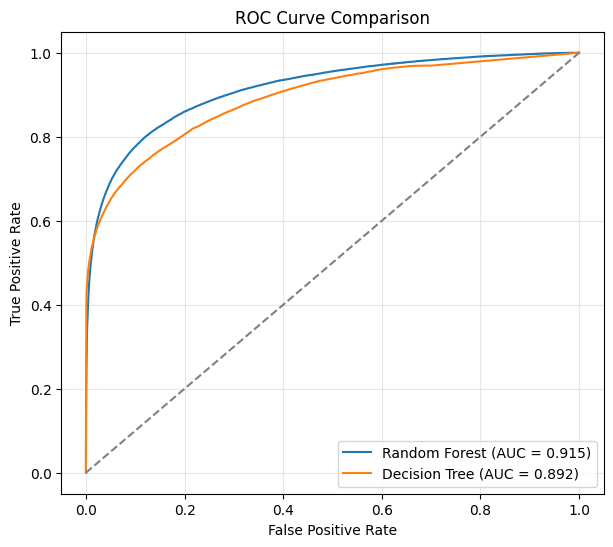

In [25]:
from sklearn.metrics import roc_curve, auc

plt.figure(figsize=(7, 6))

# random forest
rf_fpr, rf_tpr, _ = roc_curve(y_test, y_proba_rf)
rf_auc = auc(rf_fpr, rf_tpr)
plt.plot(rf_fpr, rf_tpr, label=f"Random Forest (AUC = {rf_auc:.3f})")

# decision tree
dt_fpr, dt_tpr, _ = roc_curve(y_test, y_proba)
dt_auc = auc(dt_fpr, dt_tpr)
plt.plot(dt_fpr, dt_tpr, label=f"Decision Tree (AUC = {dt_auc:.3f})")

# plot
plt.plot([0, 1], [0, 1], "--", color="gray")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend()
plt.grid(alpha=0.3)

plt.show()


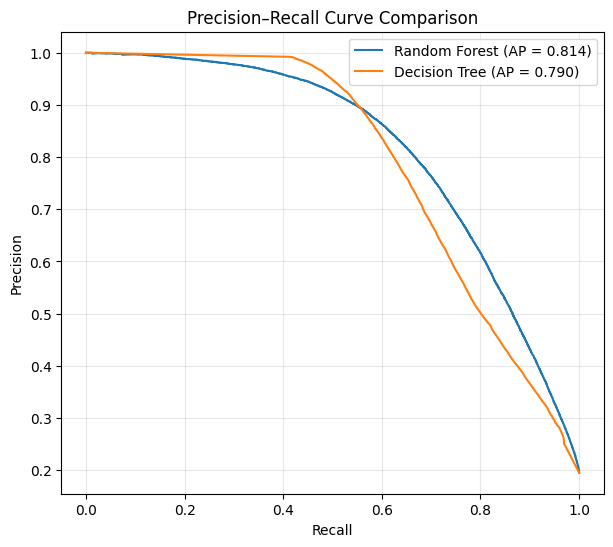

In [26]:
from sklearn.metrics import precision_recall_curve, average_precision_score
plt.figure(figsize=(7, 6))

# ---- Random Forest ----
rf_prec, rf_rec, _ = precision_recall_curve(y_test, y_proba_rf)
rf_ap = average_precision_score(y_test, y_proba_rf)
plt.plot(rf_rec, rf_prec, label=f"Random Forest (AP = {rf_ap:.3f})")

# ---- Decision Tree ----
dt_prec, dt_rec, _ = precision_recall_curve(y_test, y_proba)
dt_ap = average_precision_score(y_test, y_proba)
plt.plot(dt_rec, dt_prec, label=f"Decision Tree (AP = {dt_ap:.3f})")

# ---- Labels ----
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision–Recall Curve Comparison")
plt.legend()
plt.grid(alpha=0.3)

plt.show()


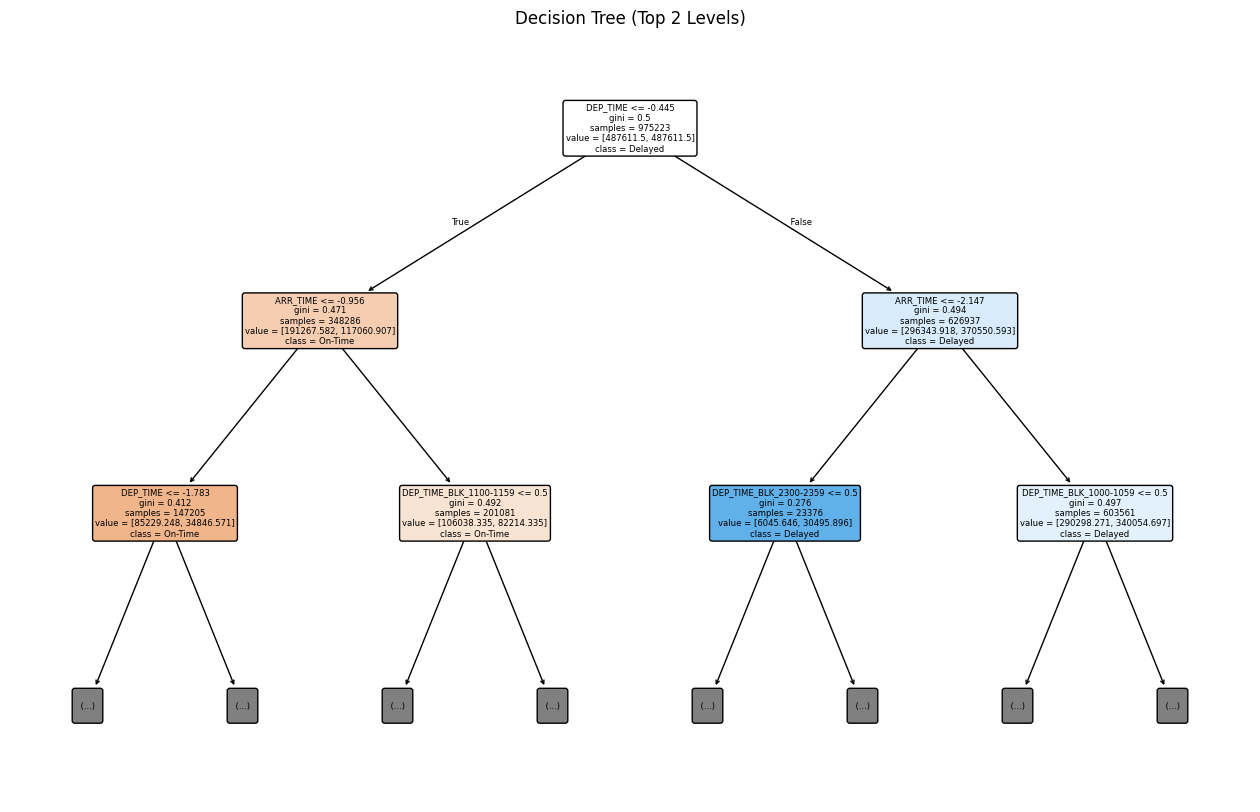

In [30]:
from sklearn import tree
import matplotlib.pyplot as plt

plt.figure(figsize=(16, 10))
plot_tree(
    dt,
    feature_names=X_test_final_df.columns,
    class_names=["On-Time", "Delayed"],
    filled=True,
    rounded=True,
    max_depth=2          # limit depth for readability
)
plt.title("Decision Tree (Top 2 Levels)")
plt.show()
